In [1]:
import os
import pandas as pd
import numpy as np
import scipy
import math
import plotnine
import matplotlib.pyplot as plt
import warnings
from scipy.integrate import solve_ivp
from datetime import datetime
from datetime import timedelta
from scipy.interpolate import interp1d

In [2]:
all_scalings= pd.read_csv("../data/scaling_relationships_calc.csv")

half_sats_p = pd.read_csv("../data/scaling_relationships_calc.csv")
half_sats_n = pd.read_csv("../data/scaling_relationships_calc.csv")

def get_half_sat(Taxon,nutrient="P"):
    half_sats=half_sats_n
    if nutrient=="P":
        return float(half_sats.loc[half_sats.taxon==Taxon,
                               "half_sat_p"])
    
    return float(half_sats.loc[half_sats.taxon==Taxon,
                               "half_sat_n"])

temp_relation=pd.read_csv("../../2026_08_29_complete_workflow/output_estimation_logN_linP_20260918/temp_relation/temperature_mean_std.csv")
def get_temp_params(Taxon,param="mean"):
    if len(temp_relation.loc[temp_relation.Order==Taxon,"mean_temp"])==0 & (param=="mean"):
        return 8
    if len(temp_relation.loc[temp_relation.Order==Taxon,"mean_temp"])==0 & (param=="std"):
        return 5
    if param=="mean":
        if len(temp_relation.loc[temp_relation.Order==Taxon,"mean_temp"])==0 | \
            (temp_relation.loc[temp_relation.Order==Taxon,"mean_temp"].iloc[0]\
           !=temp_relation.loc[temp_relation.Order==Taxon,"mean_temp"].iloc[0]):
            return 8
        return float(temp_relation.loc[temp_relation.Order==Taxon,"mean_temp"])
    if param=="std":
        if len(temp_relation.loc[temp_relation.Order==Taxon,"std_temp"])==0 | \
           (temp_relation.loc[temp_relation.Order==Taxon,"std_temp"].iloc[0]\
           !=temp_relation.loc[temp_relation.Order==Taxon,"std_temp"].iloc[0]):
            return 5
        return float(temp_relation.loc[temp_relation.Order==Taxon,"std_temp"])

In [3]:
def get_half_sats_model():
    half_sats_p_temp = pd.read_csv("../../2026_08_29_complete_workflow/output_estimation_logN_linP_20260918/half_sats/phosphorus_half_sats.csv")
    half_sats_p_temp = half_sats_p_temp.loc[half_sats_p_temp.exponential_p_val < 0.11,:]
    half_sats_n_temp = pd.read_csv("../../2026_08_29_complete_workflow/output_estimation_logN_linP_20260918/half_sats/nitrogen_half_sats.csv")
    half_sats_n_temp = half_sats_n_temp.loc[half_sats_n_temp.exponential_p_val < 0.11,:]
    return list(set(half_sats_p_temp.Taxon).union(set(half_sats_n_temp.Taxon)))
organisms_for_model = get_half_sats_model() #list(set(half_sats_p.taxon).union(set(half_sats_n.taxon)))

In [4]:
def get_max_gr(taxon):
    return float(all_scalings.loc[all_scalings.taxon==taxon,"max_growth_rate"])

### parameters from the 2026 exercise
consistent_k_light = 500
consistent_T_opt = 8
consistent_std_T = 5
consistent_max_gr = 1
consistent_half_sat_silicon = 1
consistent_half_sat_metab = 0.5
consistent_half_sat_nitr = 1
consistent_half_sat_phos = 0.1

params_frame={}
for organism in organisms_for_model:
    half_sat_nitr = get_half_sat(organism,"N")
    half_sat_phos = get_half_sat(organism,"P")
    if half_sat_nitr == "not_found":
        half_sat_nitr = consistent_half_sat_nitr
    if half_sat_phos == "not_found":
        half_sat_phos = consistent_half_sat_phos
    max_gr=consistent_max_gr # change to maximum weighted biomass
    
    current_org_dict={"max_gr":get_max_gr(organism),
                      "half_sat_nitr":half_sat_nitr,
                      "half_sat_phos":half_sat_phos,
                      "T_opt":get_temp_params(organism,"mean"),
                      "std_T":get_temp_params(organism,"std")}
    params_frame[organism]=current_org_dict

/tmp/ipykernel_1512481/800137099.py:12: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
/tmp/ipykernel_1512481/800137099.py:9: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
/tmp/ipykernel_1512481/3987653560.py:2: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
/tmp/ipykernel_1512481/800137099.py:26: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
/tmp/ipykernel_1512481/800137099.py:32: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead


In [5]:
def identify_limiting_nutrient(mm_n,mm_p,mm_s,mm_m):
    return min(mm_n,mm_p,mm_s,mm_m)

## notes - now doing this per day - but continue to include light variability over the year
## by averaging the total light over the course of the day (lower average during darker months)
def calculate_growth_rate(k_light, mu_max, T_opt, std_T, 
                          limiting_resource, Temp, Light, mortality_rate):
    light_sensitivity = 1 #Light / (k_light + Light)
    temp_sensitivity = np.exp(-((Temp - T_opt)/(std_T*2))**2)
    GR = mu_max * limiting_resource * light_sensitivity * temp_sensitivity
    return GR

def calculate_limiting_original(half_sat, Resource, maxResource):
    if Resource < 0:
        Resource = 0
    U = Resource / (half_sat + Resource)
    return U

def calculate_limiting(half_sat, Resource, maxResource):
    
    if Resource < 0:
        Resource = 0
    beta = 0.5
    inhibition_constant = half_sat
    U = Resource / (Resource + half_sat)
    #U = (Resource - half_sat / 2)/ (half_sat + Resource + (Resource**2) / inhibition_constant)
    U = (Resource)/ (half_sat + Resource + (Resource**2) / inhibition_constant)

    
    if (U < 0)|(Resource<0.001):#|(Resource<(half_sat/5)):
        U = 0
    return U

def calculate_all_limiting(organism_list, parameters, resource_code,
                         Resource, maxResource, temp_curr, light_curr):
    limiting_list=[]
    for organism in organism_list:
        if resource_code == "Nitr":
            half_sat_nitr=parameters[organism]["half_sat_nitr"]
            limiting_list.append(calculate_limiting(half_sat_nitr, 
                                                Resource, 
                                                maxResource))
        elif resource_code == "Phos":
            half_sat_phos=parameters[organism]["half_sat_phos"]
            limiting_list.append(calculate_limiting(half_sat_phos, 
                                                Resource, 
                                                maxResource))
   
    return limiting_list

def holling_type_three(half_sat_graz, phyto_density, refuge_phyto, graz_max):
    return graz_max * (phyto_density**2) / \
        (half_sat_graz**2+(phyto_density**2))
  
def ivlev_grazing(half_sat_graz, saturation_rate, phyto_density, graz_max):
    return graz_max  * (1-np.exp(-saturation_rate*phyto_density))

def transporter_model_all_resource(time, state, organism_list, parameters, time_vect, sub_frame_temp):
    curr_index = int(time)
    
    if curr_index % 15 == 1: #nitr.DateTime[curr_index].day==1:
        print(curr_index,flush=True)
        state[-2] = float(nitr_with_index.loc[nitr_with_index["index"]==curr_index-1,
                                              "nitrogen"].iloc[0])
        state[-1] = float(phos_with_index.loc[phos_with_index["index"]==curr_index-1,
                                              "phosphorus"].iloc[0])
        
    ## read in environmental variables
    light_curr = light[curr_index] # light
    temp_curr = sub_frame_temp.\
        loc[sub_frame_temp["index"]==curr_index,\
            "temperature_daily"].iloc[0] # temperature
    
    nitr_curr=state[-2]
    phos_curr=state[-1]
    max_nitr = np.max(nitr_with_index.nitrogen)
    max_phos = np.max(phos_with_index.phosphorus)
    
    chl_curr = 10 # ug/L
    mortality_rate = 0.2
    zoop_mortality = 0.01
    graz_max = 0.5
    half_sat_graz = 0.5
    saturation_rate = 0.693/half_sat_graz
    refuge_phyto = 0.25 # population at which grazing is alleviated (they're hiding)
    
    half_sat_Phy = 0.5
    assimilation = 0.4

    limiting_vect_Nitr = calculate_all_limiting(organism_list,
                                                parameters, resource_code = "Nitr",
                             Resource=nitr_curr, maxResource = max_nitr,
                             temp_curr=temp_curr, light_curr=light_curr)
    
    limiting_vect_Phos = calculate_all_limiting(organism_list,
                                                parameters, resource_code = "Phos",
                             Resource=phos_curr, maxResource = max_phos,
                             temp_curr=temp_curr, light_curr=light_curr)

    n_limiting.append([time,limiting_vect_Nitr])
    p_limiting.append([time,limiting_vect_Phos])
    
    growth_rates=[]
    grazing_rates=[]
    growth_multipliers=[]
    increase_phytos=[]
    d_phytos=[]
    for curr_org,ind_org in zip(organism_list,range(len(organism_list))):
        mu_max = parameters[curr_org]["max_gr"]
        
        limiting_resource = min(limiting_vect_Nitr[ind_org],
                                limiting_vect_Phos[ind_org])
            
        if limiting_vect_Nitr[ind_org] == limiting_resource:
            growth_multiplier = limiting_vect_Nitr[ind_org] 
        else:
            growth_multiplier = limiting_vect_Phos[ind_org]
        
        growth_multipliers.append(growth_multiplier)
        limiting_resources.append([time,limiting_resource])
        k_light = consistent_k_light
        T_opt = parameters[curr_org]["T_opt"]
        std_T = parameters[curr_org]["std_T"]
        gr_curr=calculate_growth_rate(k_light, mu_max, T_opt, 
                                      std_T, limiting_resource, temp_curr,
                                      light_curr, mortality_rate)
        #if gr_curr > 3:
        #    gr_curr = 3
        graz_curr=holling_type_three(half_sat_graz,state[ind_org],
                                     refuge_phyto,graz_max)
        
        graz_curr=ivlev_grazing(half_sat_graz, saturation_rate, 
                                state[ind_org], graz_max)
        #print("graz_curr",graz_curr,flush=True)
        growth_rates.append(gr_curr)
        grazing_rates.append(graz_curr)
        increase_phytos.append(gr_curr*(state[ind_org]+0.01))
        d_phytos.append(gr_curr*(state[ind_org]+0.01)-graz_curr*state[-3]-\
                        mortality_rate*state[ind_org]**2)

        
    
    d_zoop = assimilation * sum(grazing_rates) * (state[-3]+0.01) - \
             zoop_mortality * (state[-3]+0.01)
    d_nitr = ((mortality_rate * sum(state[0:-3]**2) +
              (1-assimilation) * sum(grazing_rates) * state[-3] + 
              zoop_mortality * state[-3] - \
              sum(increase_phytos)))*16/17
    d_phos = ((mortality_rate * sum(state[0:-3]**2) +
              (1-assimilation) * sum(grazing_rates) * state[-3] + 
              zoop_mortality * state[-3] - \
              sum(increase_phytos)))*1/17
    
    return d_phytos + [d_zoop,d_nitr,d_phos]

### FUNCTION FOR INFILLING DATA ON DAYS TO GET NEAREST MONTH ###

def diff_month(d1, d2):
    return (d1.year - d2.year) * 12 + d1.month - d2.month

def infill_data(ptown_data_input,variable_in):
    for curr in range(0,len(ptown_data_input.index)):
        if ptown_data_input[variable_in][curr]!=ptown_data_input[variable_in][curr]: ## if data missing
            variable_differences = pd.DataFrame({"var_diff": ptown_data_input["DateMonthYr"]-ptown_data_input.DateTime[curr],
                                                 "date_month_yr": ptown_data_input.DateMonthYr,
                                                 "month": ptown_data_input.Month,
                                                 "variable": ptown_data_input[variable_in],
                                                 "index": list(range(0,len(ptown_data_input.index)))})
            variable_differences=variable_differences.drop_duplicates(subset=["date_month_yr"])
            variable_differences = variable_differences.loc[variable_differences["variable"]==variable_differences["variable"],:]
            variable_differences_1=variable_differences.copy(deep=True)
            variable_differences_1["abs_diff"] = np.abs(variable_differences_1.var_diff)
            variable_differences_1 = variable_differences_1.loc[[curr>timedelta(0) for curr in variable_differences_1.var_diff],:]
            variable_differences_1 = variable_differences_1.sort_values("abs_diff",ascending=True).head(n=1) ## get the closest values
           
            variable_differences_2=variable_differences.copy(deep=True)
            variable_differences_2["abs_diff"] = np.abs(variable_differences_2.var_diff)
            variable_differences_2 = variable_differences_2.loc[[curr<timedelta(0) for curr in variable_differences_2.var_diff],:]
            variable_differences_2 = variable_differences_2.sort_values("abs_diff",ascending=True).head(n=1)
            variable_differences_2 = variable_differences_2.sort_values("date_month_yr")
            
            variable_differences_1 = pd.concat([variable_differences_1,variable_differences_2]).reset_index()

            value_out = variable_differences_1["variable"][0] +\
                (variable_differences_1["variable"][1] - variable_differences_1["variable"][0]) / \
                diff_month(variable_differences_1.date_month_yr[0],
                           variable_differences_1.date_month_yr[1])
            
            if (variable_in=="temperature")&(ptown_data_input.Month[curr]):
                value_out = variable_differences_1["variable"][0] -\
                (variable_differences_1["variable"][1] - variable_differences_1["variable"][0]) / \
                diff_month(variable_differences_1.date_month_yr[0],
                           variable_differences_1.date_month_yr[1])

            ptown_data_input[variable_in][curr] = value_out
    return ptown_data_input

In [6]:
irradiance = pd.read_csv("../data/irradiance.csv")
time_vect = pd.date_range(datetime.strptime('2000-02-01 00:00',"%Y-%m-%d %H:%M"),
                          datetime.strptime("2023-10-30 00:00","%Y-%m-%d %H:%M"), freq='h')
month_vect = [dt.month for dt in time_vect]
hour_vect = [dt.hour for dt in time_vect]
set_zeros_1 = [max(0,hr_curr-6-round(abs(mnth_curr-6)/3,0)) for hr_curr,mnth_curr in zip(hour_vect,month_vect)]
set_zeros_2 = [max(0,22-abs(mnth_curr-6)-hr_curr) for hr_curr,mnth_curr in zip(hour_vect,month_vect)]
light = [2500  / np.sqrt(max(1,abs(6-mnth_curr)))  * np.sin(np.pi/2 * \
                                                            min(set_zeros_1_c,set_zeros_2_c)/max(set_zeros_1_c,set_zeros_2_c))\
         for mnth_curr,set_zeros_1_c,set_zeros_2_c in zip(month_vect,set_zeros_1,set_zeros_2)] 
## light is normalized to a daily cycle - more light happens in June & day is longer.
## in June, sunlight is from ~6am to 9pm, in December it's from ~9am to 4pm. 

light_fr=pd.DataFrame({"light":light,"DateTime":time_vect})
light_fr["Year"] = [dt.year for dt in light_fr.DateTime]
light_fr["Month"] = [dt.month for dt in light_fr.DateTime]
light_fr["Day"] = [dt.day for dt in light_fr.DateTime]
light_fr["Hour"] = [dt.hour for dt in light_fr.DateTime]
light_fr = light_fr.groupby(["Year","Month","Day"]).light.mean().reset_index()

light = list(light_fr.light)

### TEMPERATURE CALCULATION ###
time_vect = pd.date_range(datetime.strptime('2000-02-01 00:00',"%Y-%m-%d %H:%M"),
                          datetime.strptime("2023-11-01 00:00","%Y-%m-%d %H:%M"), freq='M')

temps_ptown = pd.read_csv("../data/temperatures.csv")

temps_ptown["Date"]=[datetime.strptime(date_string, "%Y-%m-%d") for date_string in temps_ptown.Date]
temps_ptown = temps_ptown.groupby(["Date","STAT_ID"]).FFU_RESULT.mean().reset_index().\
    rename({"FFU_RESULT":"temperature"},axis="columns")

temps_ptown["DateMonthYr"] = [dt.replace(day=1) for dt in temps_ptown["Date"]]
temps_ptown = temps_ptown.sort_values("DateMonthYr")
temps_ptown["Month"] = [dt.month for dt in temps_ptown["Date"]]
temps_ptown["Year"] = [dt.year for dt in temps_ptown["Date"]]

to_infill = pd.DataFrame({"DateTime":time_vect})
to_infill["Year"] = [dt.year for dt in to_infill.DateTime]
to_infill["Month"] = [dt.month for dt in to_infill.DateTime]
to_infill["Hour"] = [dt.hour for dt in to_infill.DateTime]
to_infill = to_infill.merge(temps_ptown,on=["Month","Year"],how="left")
temp_1 = infill_data(to_infill,"temperature")

time_vect = pd.date_range(datetime.strptime('2000-02-01 00:00',"%Y-%m-%d %H:%M"),
                          datetime.strptime("2023-10-30 00:00","%Y-%m-%d %H:%M"), freq='h')

time_frame_2 = pd.DataFrame({"DateTime":time_vect})
time_frame_2["Year"] = [dt.year for dt in time_frame_2.DateTime]
time_frame_2["Month"] = [dt.month for dt in time_frame_2.DateTime]
time_frame_2["Day"] = [dt.day for dt in time_frame_2.DateTime]
time_frame_2["Hour"] = [dt.hour for dt in time_frame_2.DateTime]
daily_temp_fr_2 = time_frame_2.merge(temp_1.loc[:,["Month","Year","temperature"]].drop_duplicates(subset=["Month","Year"]),
                     on=["Month","Year"],how="left")

daily_temp_fr_2["temperature_hourly"]=[temperature + np.sin(2*np.pi*(Hour-6)/24)/2 for temperature,Hour in\
                                       zip(daily_temp_fr_2.temperature,daily_temp_fr_2.Hour)]

daily_temp_fr_2 = daily_temp_fr_2.groupby(["Year","Month","Day"]).temperature_hourly.mean().reset_index()
#########

/tmp/ipykernel_1512481/1481900681.py:24: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
/tmp/ipykernel_1512481/2327458062.py:195: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

/tmp/ipykernel_

In [9]:
nerrs_data = pd.read_csv("../data/nerrs_data_cleaned.csv")
nerrs_data["DateTime"] = [datetime.strptime(date_curr,"%Y-%m-%d") for \
                          date_curr in nerrs_data["DateTime"]]

In [10]:
nerrs_data_temp = pd.read_csv("../data/nerrs_data_cleaned_temp.csv")
nerrs_data_temp["DateTime"] = [datetime.strptime(date_curr,"%Y-%m-%d") for \
                          date_curr in nerrs_data_temp["DateTime"]]

In [11]:
combined_sol=pd.DataFrame()
for stat_id in list(set(nerrs_data["NERR.Site.ID"])):
    sub_frame=nerrs_data.loc[nerrs_data["NERR.Site.ID"]==stat_id,:]
    sub_frame_temp_=nerrs_data_temp.loc[nerrs_data_temp["NERR.Site.ID"]==stat_id,:]
    if len(sub_frame_temp_.index)==0:
        continue
    time_vect = pd.date_range(np.min(sub_frame.DateTime),
                              np.max(sub_frame.DateTime), freq='D')

    f_nearest = interp1d(sub_frame.DateTime.astype('int64'), 
                         sub_frame.nitrogen, 
                         kind='nearest', fill_value="extrapolate")
    convert_frame=pd.DataFrame({"DateTime":time_vect})
    convert_frame["nitrogen"] = f_nearest(time_vect.astype('int64'))
    f_nearest = interp1d(sub_frame.DateTime.astype('int64'), 
                         sub_frame.phosphorus, 
                         kind='nearest', fill_value="extrapolate")
    convert_frame["phosphorus"] = f_nearest(time_vect.astype('int64'))
    
    sub_frame_temp=pd.DataFrame({"DateTime":time_vect})
    f_nearest = interp1d(sub_frame_temp_.DateTime.astype('int64'), 
                         sub_frame_temp_.Temp, 
                         kind='nearest', fill_value="extrapolate")
    sub_frame_temp["temperature_daily"] = f_nearest(time_vect.astype('int64'))
    
    dates_with_index = pd.DataFrame(time_vect,columns=["DateTime"]).reset_index()
    nitr_with_index = convert_frame.merge(dates_with_index,on="DateTime",how="inner")
    phos_with_index = convert_frame.merge(dates_with_index,on="DateTime",how="inner")
    sub_frame_temp = sub_frame_temp.merge(dates_with_index,on="DateTime",how="inner")

    n_limiting = []  # Global variable
    p_limiting = []  # Global variable
    si_limiting = []  # Global variable
    d_Hs = []
    limiting_resources = []  # Global variable
    nitrogen_start=nitr_with_index.nitrogen[0]
    phos_start = phos_with_index.phosphorus[0]

    state={}
    for org in organisms_for_model:
        state[org]=0.5
    state["zoop"]=0.5
    state["nitrogen"]=nitrogen_start
    state["phosphorus"]=phos_start

    sol = solve_ivp(transporter_model_all_resource, t_span=[0,len(time_vect)-1],
                    t_eval=list(range(0,len(time_vect)-1,1)),
                    y0=list(state.values()),args=[organisms_for_model,params_frame,time_vect,sub_frame_temp])
    phyto_frame=pd.DataFrame()
    for organism,organism_ind in zip(organisms_for_model,range(len(organisms_for_model))):
        phyto_frame[organism] = sol.y[organism_ind,:]
    phyto_frame["index"]=sol.t
    phyto_frame["zoop"] = list(sol.y[sol.y.shape[0]-3,:])
    phyto_frame["nitrogen"] = list(sol.y[sol.y.shape[0]-2,:]) #n_values
    phyto_frame["phosphorus"] = list(sol.y[sol.y.shape[0]-1,:]) #p_values
    all_sol = phyto_frame.merge(dates_with_index,on="index").melt(id_vars=["DateTime","index"],
                     var_name="taxon",value_name="abund")
    
    all_sol["Site"] = stat_id
    combined_sol = pd.concat([combined_sol,all_sol],axis=0)
    

1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
31
31
31
31
31
31
31
31
31
31
31
31
31
31
31
31
31
31
31
31
31
31
31
31
31
31
31
31
31
31
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
46
61
61
61
61
61
61
61
61
61
61
61
61
61
61
61
61
61
61
61
61
61
61
61
61
61
61
61
61
61
61
61
61
61
76
76
76
76
76
76
76
76
76
76
76
76
76
76
76
76
76
76
76
76
91
91
91
91
91
91
91
91
91
91
91
91
91
91
91
91
91
91
91
106
106
106
106
106
106
106
106
106
106
106
106
106
106
106
106
106
106
106
106
106
106
106
121
121
121
121
121
121
121
121
121
121
121
121
121
121
121
121
121
121
121
121
121
121
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
31
31
31
31
31
31
31
31
31
31
31
31
31
31
31
31
31
31
31
31

/tmp/ipykernel_1512481/2327458062.py:56: RuntimeWarning: overflow encountered in exp
/tmp/ipykernel_1512481/2327458062.py:138: RuntimeWarning: invalid value encountered in scalar multiply
/tmp/ipykernel_1512481/2327458062.py:52: RuntimeWarning: invalid value encountered in scalar divide
/tmp/ipykernel_1512481/2327458062.py:137: RuntimeWarning: invalid value encountered in scalar multiply
/tmp/ipykernel_1512481/2327458062.py:145: RuntimeWarning: invalid value encountered in scalar add
/tmp/ipykernel_1512481/2327458062.py:149: RuntimeWarning: invalid value encountered in scalar add
/users/akrinos/miniconda3/envs/glm_new/lib/python3.13/site-packages/scipy/integrate/_ivp/rk.py:109: RuntimeWarning: invalid value encountered in divide


3286
3286
3286
3286
3286
3286
3301
3301
3301
3301
3301
3301
3301
3301
3301
3301
3301
3301
3301
3301
3301
3301
3301
3301
3316
3316
3316
3316
3316
3316
3316
3316
3331
3331
3331
3331
3331
3331
3346
3346
3346
3346
3346
3346
3346
3346
3361
3361
3361
3361
3361
3361
3361
3376
3376
3376
3376
3376
3376
3376
3391
3391
3391
3391
3391
3391
3391
3391
3391
3391
3391
3391
3391
3391
3391
3391
3391
3391
3406
3406
3406
3406
3406
3406
3406
3406
3406
3421
3421
3421
3421
3421
3421
3421
3421
3436
3436
3436
3436
3436
3436
3436
3436
3451
3466
3466
3466
3466
3466
3466
3466
3466
3481
3481
3481
3481
3496
3496
3511
3511
3511
3511
3511
3526
3526
3541
3541
3556
3556
3556
3556
3556
3556
3556
3571
3571
3586
3586
3586
3586
3586
3586
3586
3586
3586
3586
3586
3586
3601
3601
3601
3601
3601
3601
3601
3601
3601
3601
3601
3616
3616
3616
3616
3616
3616
3631
3631
3631
3631
3631
3631
3631
3631
3631
3631
3631
3631
3631
3631
3631
3631
3631
3631
3631
3631
3646
3646
3646
3646
3646
3646
3646
3646
3646
3646
3646
3646
3646
3646
3646


/tmp/ipykernel_1512481/2327458062.py:138: RuntimeWarning: invalid value encountered in scalar subtract


4351
4351
4351
4351
4351
4351
4351
4351
4366
4366
4366
4366
4366
4366
4366
4381
4381
4381
4381
4381
4381
4381
4381
4381
4396
4396
4396
4396
4396
4396
4396
4396
4411
4411
4411
4411
4411
4411
4411
4411
4411
4411
4411
4411
4426
4426
4426
4426
4426
4426
4426
4441
4441
4441
4441
4441
4441
4441
4441
4441
4441
4441
4441
4441
4441
4456
4456
4456
4456
4456
4456
4456
4456
4471
4471
4471
4471
4471
4471
4471
4471
4471
4486
4486
4486
4486
4486
4486
4486
4486
4486
4486
4486
4486
4486
4501
4501
4501
4501
4501
4516
4516
4516
4516
4516
4531
4531
4531
4531
4531
4531
4531
4531
4531
4546
4546
4576
4576
4576
4576
4576
4576
4576
4591
4591
4591
4591
4606
4636
4636
4636
4651
4651
4651
4651
4651
4651
4651
4651
4651
4651
4651
4666
4666
4666
4666
4666
4681
4681
4681
4681
4681
4681
4696
4696
4696
4696
4696
4696
4696
4711
4711
4711
4711
4711
4711
4711
4711
4711
4726
4726
4726
4726
4726
4726
4741
4741
4741
4741
4741
4741
4741
4741
4756
4756
4756
4756
4756
4756
4756
4756
4771
4771
4771
4771
4771
4771
4771
4771
4771


...

3181
3181
3181
3181
3181
3181
3181
3181
3181
3181
3181
3181
3196
3196
3196
3196
3196
3196
3196
3196
3196
3196
3211
3211
3211
3211
3211
3211
3211
3211
3226
3226
3226
3226
3226
3226
3226
3226
3226
3226
3226
3226
3226
3226
3226
3226
3226
3241
3241
3241
3241
3241
3241
3241
3241
3241
3241
3241
3241
3241
3241
3241
3241
3241
3241
3256
3256
3256
3256
3256
3256
3256
3256
3256
3256
3256
3256
3256
3256
3256
3271
3271
3271
3271
3271
3271
3271
3271
3271
3271
3271
3271
3271
3271
3271
3271
3271
3271
3286
3286
3286
3286
3286
3286
3286
3286
3286
3286
3301
3301
3301
3301
3301
3301
3301
3301
3301
3301
3301
3301
3301
3301
3301
3301
3301
3301
3301
3301
3301
3301
3301
3301
3316
3316
3316
3316
3316
3316
3316
3316
3316
3316
3331
3331
3331
3331
3331
3331
3331
3346
3346
3346
3346
3346
3346
3346
3346
3346
3346
3346
3361
3361
3361
3361
3361
3361
3361
3361
3361
3361
3361
3361
3361
3361
3361
3361
3361
3376
3376
3376
3376
3391
3391
3391
3391
3391
3391
3391
3391
3391
3391
3406
3406
3406
3406
3406
3406
3406
3406
3421


/tmp/ipykernel_1512481/2327458062.py:138: RuntimeWarning: invalid value encountered in scalar subtract


3556
3556
3556
3556
3556
3556
3556
3556
3556
3556
3556
3556
3556
3556
3556
3556
3556
3556
3556
3556
3556
3556
3556
3556
3556
3556
3556
3571
3571
3571
3571
3571
3571
3571
3571
3571
3571
3571
3571
3571
3571
3571
3571
3571
3571
3571
3571
3571
3571
3571
3586
3586
3586
3586
3586
3586
3586
3586
3586
3586
3586
3586
3586
3586
3586
3586
3586
3586
3586
3586
3586
3586
3586
3586
3601
3601
3601
3601
3601
3601
3601
3601
3601
3601
3601
3601
3601
3601
3601
3601
3601
3616
3616
3616
3616
3616
3616
3616
3616
3616
3616
3616
3616
3616
3616
3616
3616
3616
3616
3631
3631
3631
3631
3631
3631
3631
3631
3631
3631
3631
3631
3631
3631
3631
3646
3646
3646
3646
3646
3646
3646
3646
3661
3661
3661
3661
3661
3661
3661
3661
3661
3661
3661
3661
3661
3661
3661
3661
3661
3661
3661
3661
3661
3661
3661
3676
3676
3676
3676
3676
3676
3676
3676
3676
3676
3676
3676
3691
3691
3691
3691
3691
3691
3691
3691
3691
3691
3691
3691
3691
3691
3691
3691
3691
3691
3691
3706
3706
3706
3706
3706
3706
3706
3706
3721
3721
3721
3721
3721
3721


/tmp/ipykernel_1512481/2327458062.py:56: RuntimeWarning: overflow encountered in exp


301
301
301
301
301
301
301
301
301
301
301
301
301
301
301
301
301
301
301
301
301
301
301
301
301
301
301
301
301
301
301
301
301
301
301
301
301
301
301
301
316
316
316
316
316
316
316
316
316
316
316
316
316
316
316
316
316
316
316
316
316
316
316
316
316
316
316
316
316
316
316
316
316
316
316
331
331
331
331
331
331
331
331
331
331
331
331
331
331
331
331
331
331
331
331
331
331
331
331
331
331
331
331
331
331
331
331
331
331
331
331
331
331
331
331
331
331
331
346
346
346
346
346
346
346
346
346
346
346
346
346
346
346
346
346
346
346
346
346
346
346
346
346
346
346
346
346
346
346
346
346
346
346
346
346
346
361
361
361
361
361
361
361
361
361
361
361
361
361
361
361
361
361
361
361
361
361
361
361
361
361
361
361
361
361
361
361
361
361
361
361
361
361
361
361
361
361
361
361
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
376
391
391
391
391
391
391


In [13]:
combined_sol.to_csv("../output/allometry_NERRS.csv")

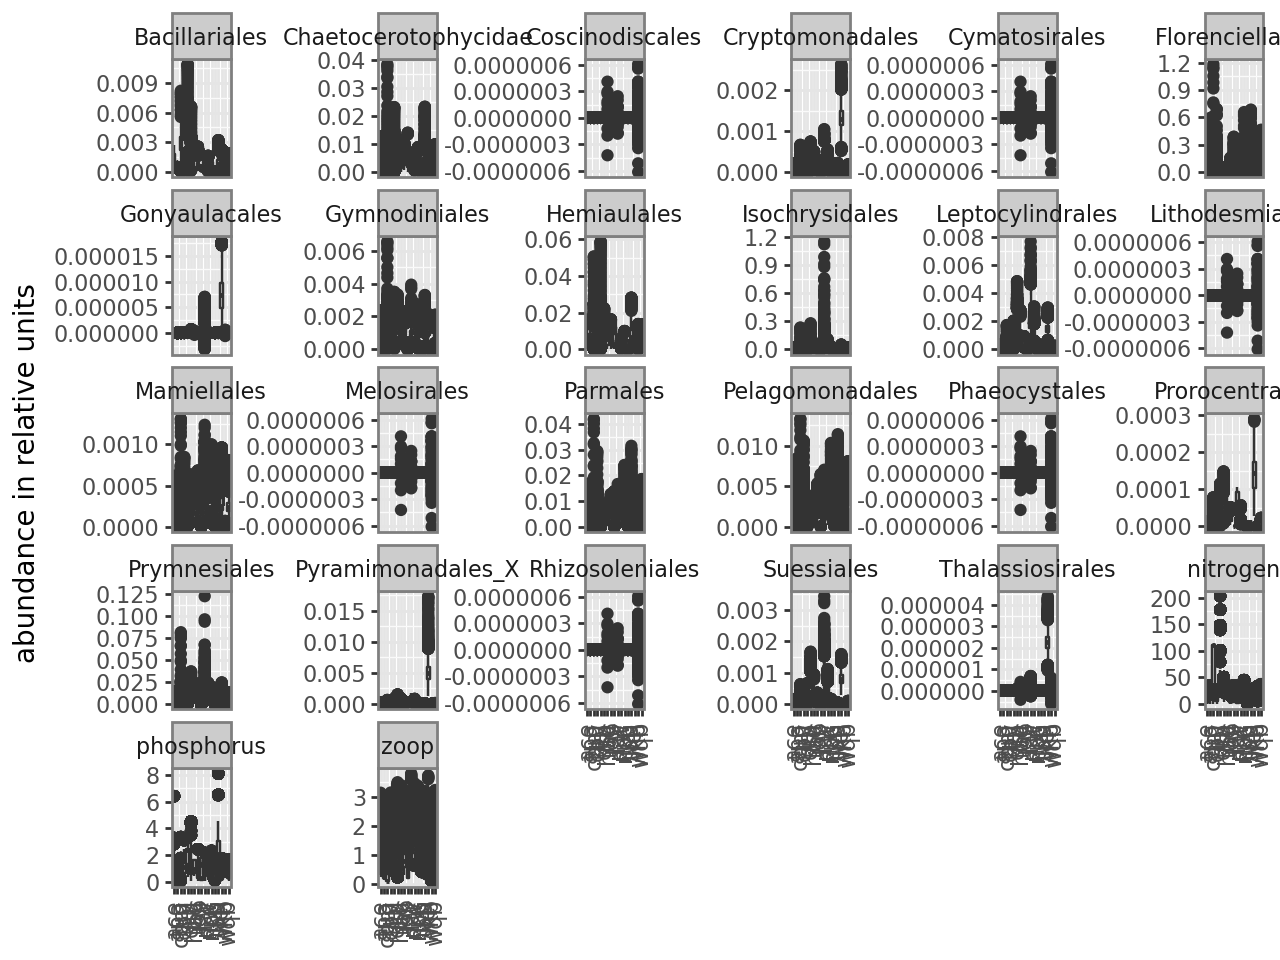

In [20]:
## plot entire timeseries
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42

zoom_in=(plotnine.ggplot(combined_sol.loc[combined_sol["index"]>50,:]) + 
    plotnine.geom_boxplot(plotnine.aes(x="Site",y="abund"),size=0.5)+ 
    #plotnine.facet_wrap("taxon",scales="free_y",ncol=1)+
    plotnine.theme_bw(base_size=10)+plotnine.ylab("abundance in relative units") + 
    plotnine.xlab("") +
    plotnine.theme(axis_text_x=plotnine.element_text(rotation=90, hjust=0.5)) +
    plotnine.facet_wrap("taxon",scales="free_y"))

zoom_in

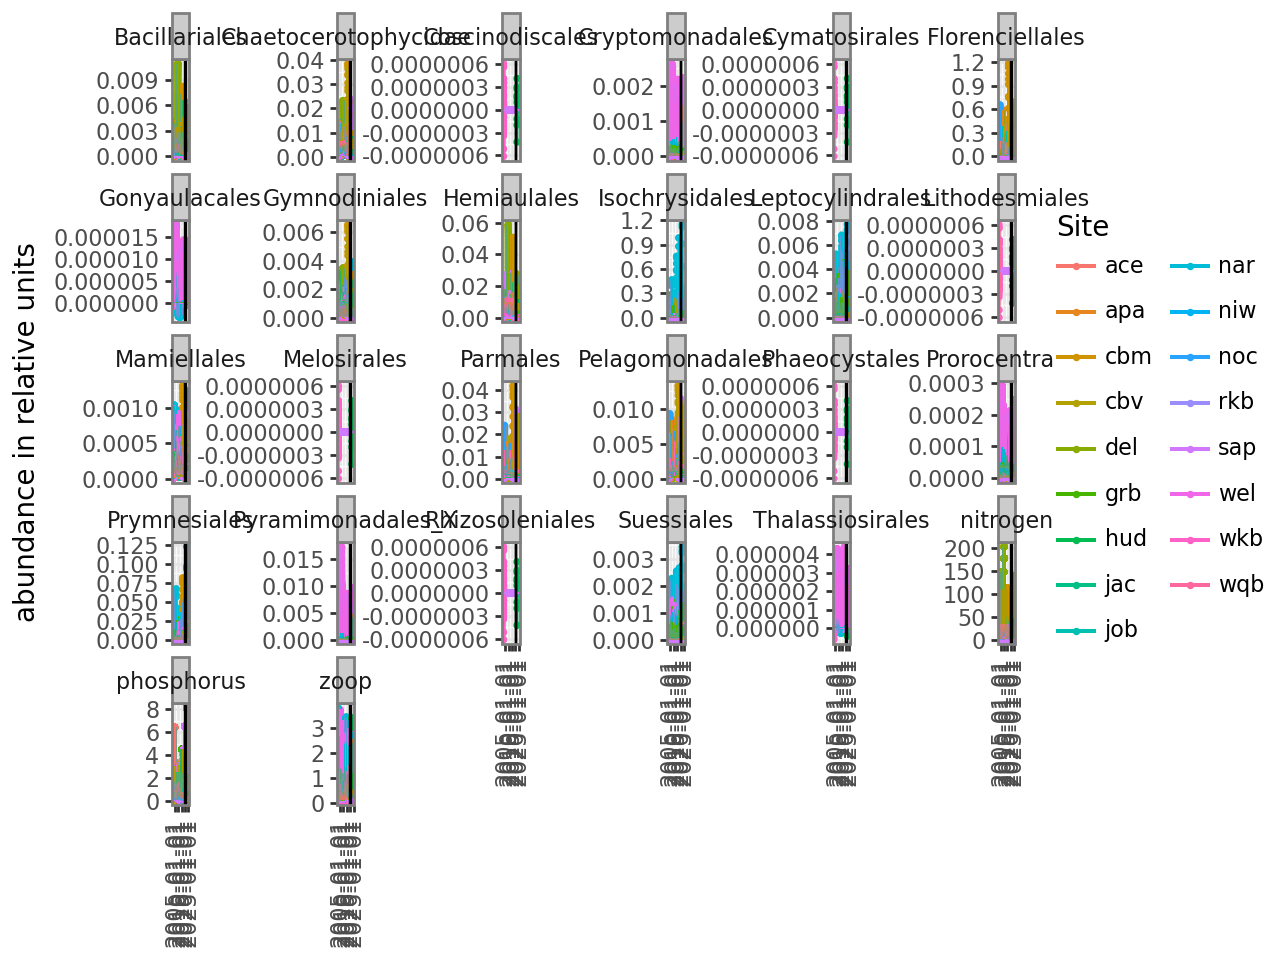

In [17]:
## plot entire timeseries
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42

zoom_in=(plotnine.ggplot(combined_sol.loc[combined_sol["index"]>50,:]) + 
    plotnine.geom_point(plotnine.aes(x="DateTime",y="abund",color="Site"),size=0.5)+ 
    plotnine.geom_line(plotnine.aes(x="DateTime",y="abund",group="taxon",
                                   color="Site")) + 
    #plotnine.facet_wrap("taxon",scales="free_y",ncol=1)+
    plotnine.theme_bw(base_size=10)+plotnine.ylab("abundance in relative units") + 
    plotnine.xlab("") +
    plotnine.theme(axis_text_x=plotnine.element_text(rotation=90, hjust=0.5)) +
    plotnine.facet_wrap("taxon",scales="free_y") +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2020-04-01", 
                                                                  "%Y-%m-%d"))) +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2021-04-01", 
                                                                  "%Y-%m-%d"))))
zoom_in

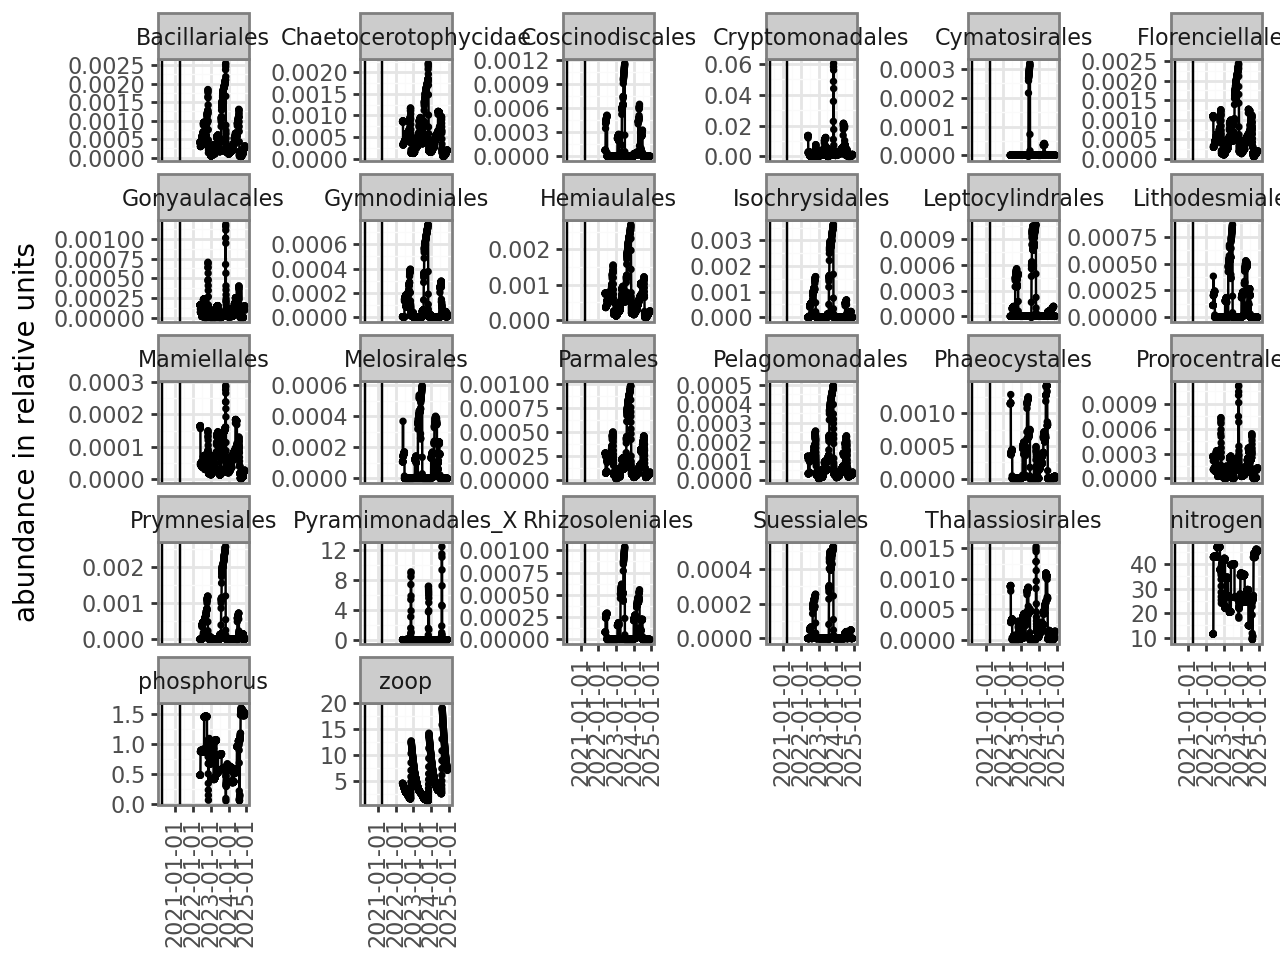

In [68]:
## plot entire timeseries
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42

zoom_in=(plotnine.ggplot(all_sol.loc[all_sol["index"]>50,:]) + 
    plotnine.geom_point(plotnine.aes(x="DateTime",y="abund"),size=0.5)+ 
    plotnine.geom_line(plotnine.aes(x="DateTime",y="abund",group="taxon")) + 
    #plotnine.facet_wrap("taxon",scales="free_y",ncol=1)+
    plotnine.theme_bw(base_size=10)+plotnine.ylab("abundance in relative units") + 
    plotnine.xlab("") +
    plotnine.theme(axis_text_x=plotnine.element_text(rotation=90, hjust=0.5)) +
    plotnine.facet_wrap("taxon",scales="free_y") +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2020-04-01", 
                                                                  "%Y-%m-%d"))) +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2021-04-01", 
                                                                  "%Y-%m-%d"))))
zoom_in

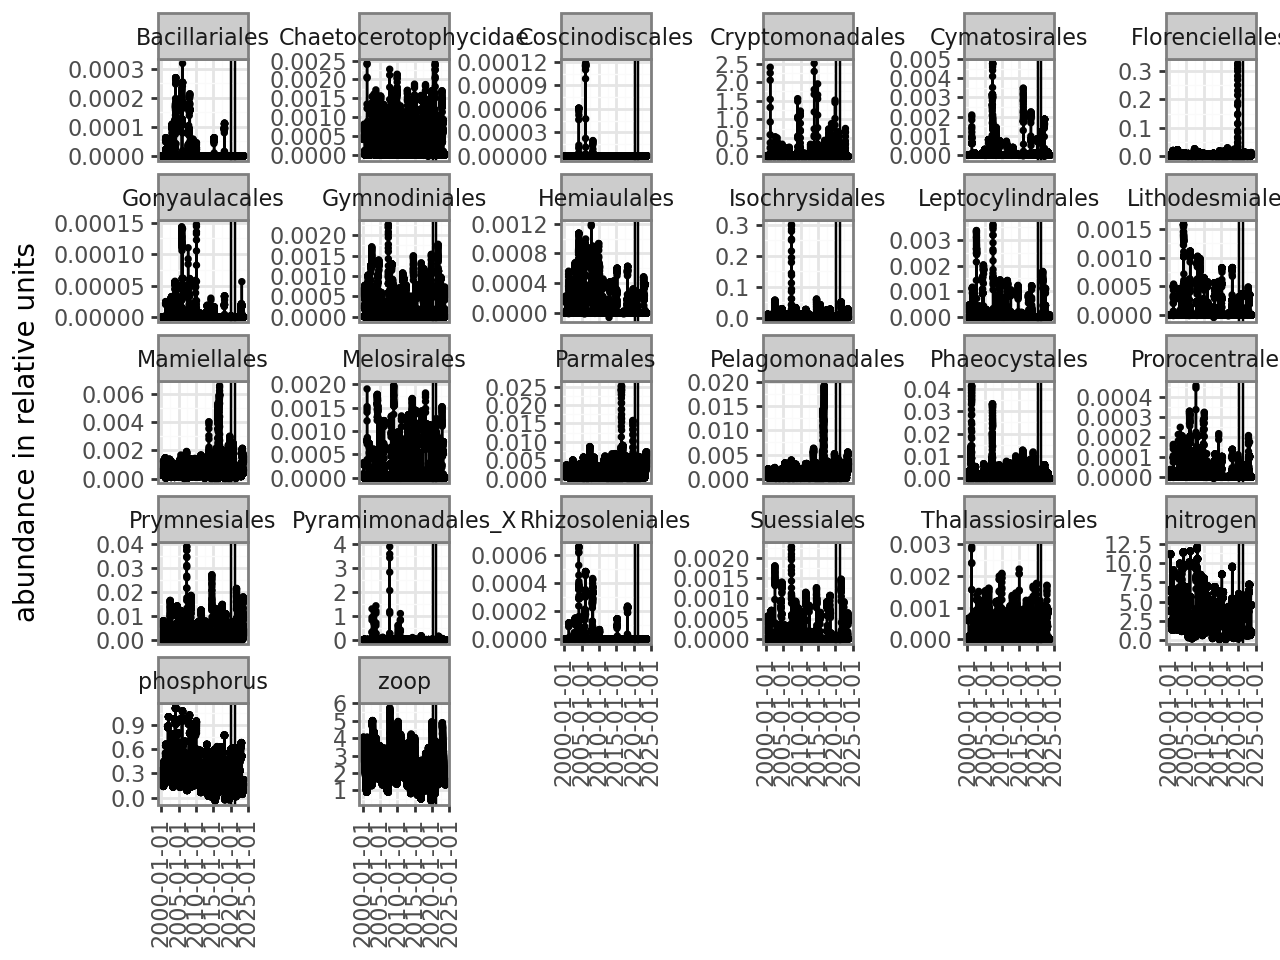

In [12]:
## plot entire timeseries
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42

zoom_in=(plotnine.ggplot(all_sol.loc[all_sol["index"]>50,:]) + 
    plotnine.geom_point(plotnine.aes(x="DateTime",y="abund"),size=0.5)+ 
    plotnine.geom_line(plotnine.aes(x="DateTime",y="abund",group="taxon")) + 
    #plotnine.facet_wrap("taxon",scales="free_y",ncol=1)+
    plotnine.theme_bw(base_size=10)+plotnine.ylab("abundance in relative units") + 
    plotnine.xlab("") +
    plotnine.theme(axis_text_x=plotnine.element_text(rotation=90, hjust=0.5)) +
    plotnine.facet_wrap("taxon",scales="free_y") +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2020-04-01", 
                                                                  "%Y-%m-%d"))) +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2021-04-01", 
                                                                  "%Y-%m-%d"))))
zoom_in

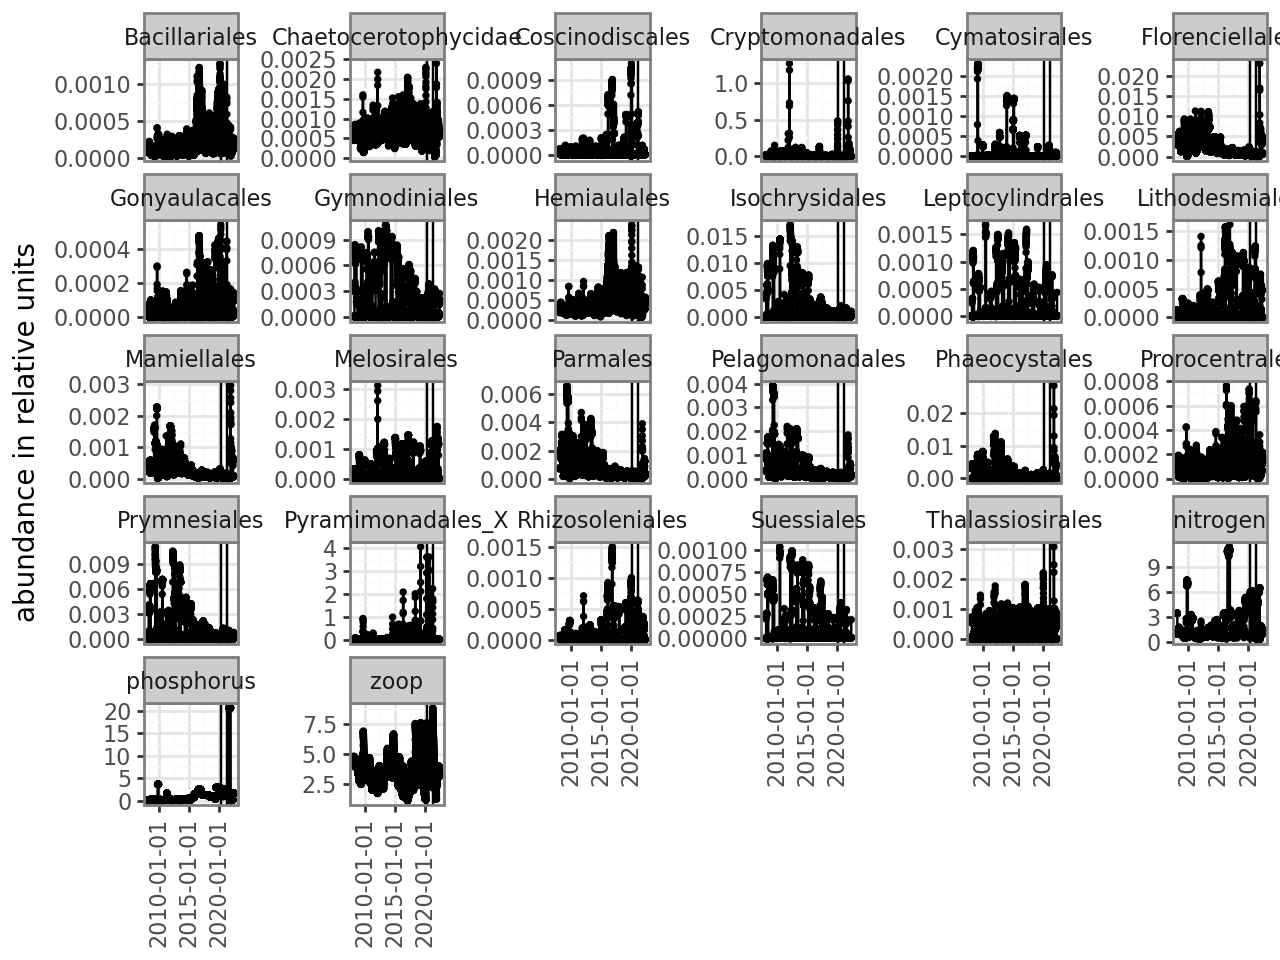

In [71]:
## plot entire timeseries
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42

zoom_in=(plotnine.ggplot(all_sol.loc[all_sol["index"]>50,:]) + 
    plotnine.geom_point(plotnine.aes(x="DateTime",y="abund"),size=0.5)+ 
    plotnine.geom_line(plotnine.aes(x="DateTime",y="abund",group="taxon")) + 
    #plotnine.facet_wrap("taxon",scales="free_y",ncol=1)+
    plotnine.theme_bw(base_size=10)+plotnine.ylab("abundance in relative units") + 
    plotnine.xlab("") +
    plotnine.theme(axis_text_x=plotnine.element_text(rotation=90, hjust=0.5)) +
    plotnine.facet_wrap("taxon",scales="free_y") +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2020-04-01", 
                                                                  "%Y-%m-%d"))) +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2021-04-01", 
                                                                  "%Y-%m-%d"))))
zoom_in

/tmp/ipykernel_3813632/2382843779.py:13: FutureWarning: Logical ops (and, or, xor) between Pandas objects and dtype-less sequences (e.g. list, tuple) are deprecated and will raise in a future version. Wrap the object in a Series, Index, or np.array before operating instead.


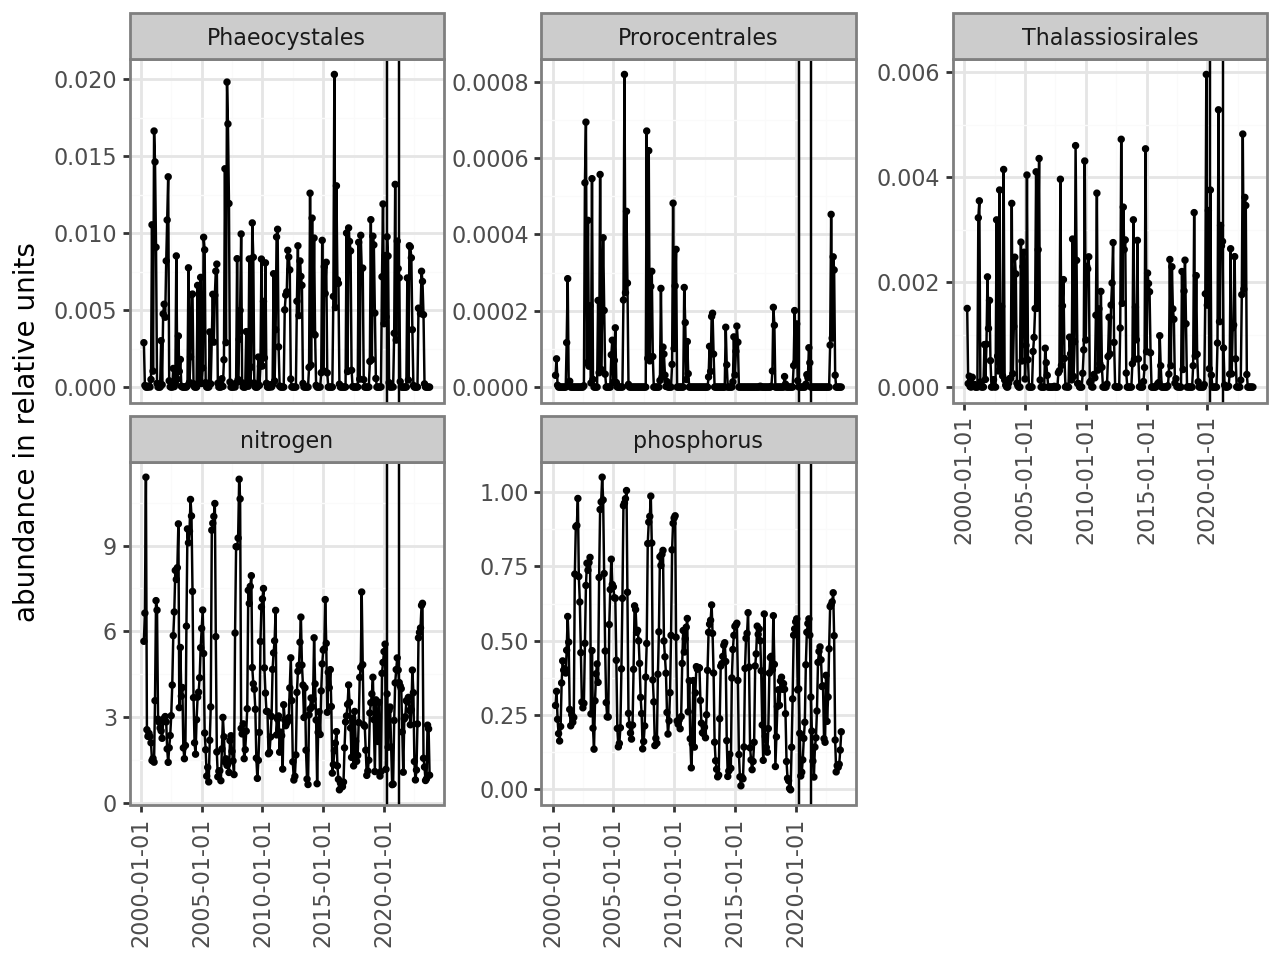

In [18]:
all_sol["month"] = [curr.month for curr in all_sol.DateTime]
all_sol["year"] = [curr.year for curr in all_sol.DateTime]
all_sol_summary = all_sol.groupby(["month","year","taxon"])[["abund","index"]].\
    mean().reset_index()
all_sol_summary["DateTime"] = [datetime(year, month, 1) for \
                               year,month in zip(all_sol_summary.year,
                                                 all_sol_summary.month)]

## plot entire timeseries
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42

zoom_in=(plotnine.ggplot(all_sol_summary.loc[(all_sol_summary["index"]>50)&\
                         ([curr in ["Phaeocystales","Thalassiosirales","Prorocentrales",
                                    "nitrogen","phosphorus"] for curr in all_sol_summary.taxon]),:]) + 
    plotnine.geom_point(plotnine.aes(x="DateTime",y="abund"),size=0.5)+ 
    plotnine.geom_line(plotnine.aes(x="DateTime",y="abund",group="taxon")) + 
    #plotnine.facet_wrap("taxon",scales="free_y",ncol=1)+
    plotnine.theme_bw(base_size=10)+plotnine.ylab("abundance in relative units") + 
    plotnine.xlab("") +
    plotnine.theme(axis_text_x=plotnine.element_text(rotation=90, hjust=0.5)) +
    plotnine.facet_wrap("taxon",scales="free_y") +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2020-04-01", 
                                                                  "%Y-%m-%d"))) +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2021-04-01", 
                                                                  "%Y-%m-%d"))))
zoom_in

/tmp/ipykernel_3813632/2459505683.py:13: FutureWarning: Logical ops (and, or, xor) between Pandas objects and dtype-less sequences (e.g. list, tuple) are deprecated and will raise in a future version. Wrap the object in a Series, Index, or np.array before operating instead.


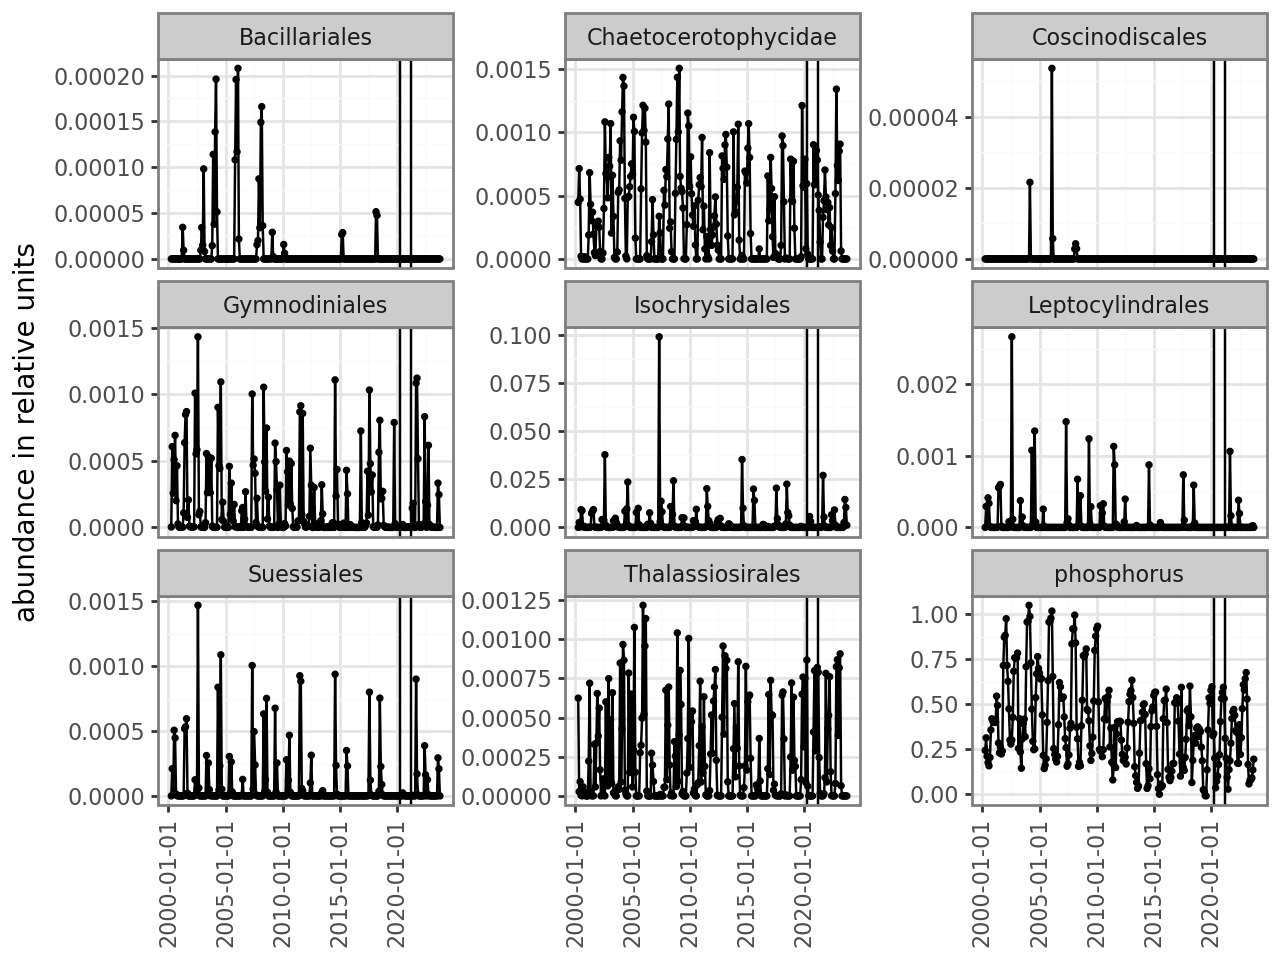

In [23]:
all_sol["month"] = [curr.month for curr in all_sol.DateTime]
all_sol["year"] = [curr.year for curr in all_sol.DateTime]
all_sol_summary = all_sol.groupby(["month","year","taxon"])[["abund","index"]].\
    mean().reset_index()
all_sol_summary["DateTime"] = [datetime(year, month, 1) for \
                               year,month in zip(all_sol_summary.year,
                                                 all_sol_summary.month)]

## plot entire timeseries
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42

zoom_in=(plotnine.ggplot(all_sol_summary.loc[(all_sol_summary["index"]>50)&\
                         ([curr in ['Leptocylindrales',
                                     'Suessiales',
                                     'Isochrysidales',
                                     'Bacillariales',
                                     'Coscinodiscales',
                                     'Gymnodiniales',
                                     'Chaetocerotophycidae',
                                     'Thalassiosirales',
                                     'Phaeocystales'
                                    "nitrogen","phosphorus"] for curr in all_sol_summary.taxon]),:]) + 
    plotnine.geom_point(plotnine.aes(x="DateTime",y="abund"),size=0.5)+ 
    plotnine.geom_line(plotnine.aes(x="DateTime",y="abund",group="taxon")) + 
    #plotnine.facet_wrap("taxon",scales="free_y",ncol=1)+
    plotnine.theme_bw(base_size=10)+plotnine.ylab("abundance in relative units") + 
    plotnine.xlab("") +
    plotnine.theme(axis_text_x=plotnine.element_text(rotation=90, hjust=0.5)) +
    plotnine.facet_wrap("taxon",scales="free_y") +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2020-04-01", 
                                                                  "%Y-%m-%d"))) +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2021-04-01", 
                                                                  "%Y-%m-%d"))))
zoom_in

/tmp/ipykernel_4033883/3237849384.py:13: FutureWarning: Logical ops (and, or, xor) between Pandas objects and dtype-less sequences (e.g. list, tuple) are deprecated and will raise in a future version. Wrap the object in a Series, Index, or np.array before operating instead.


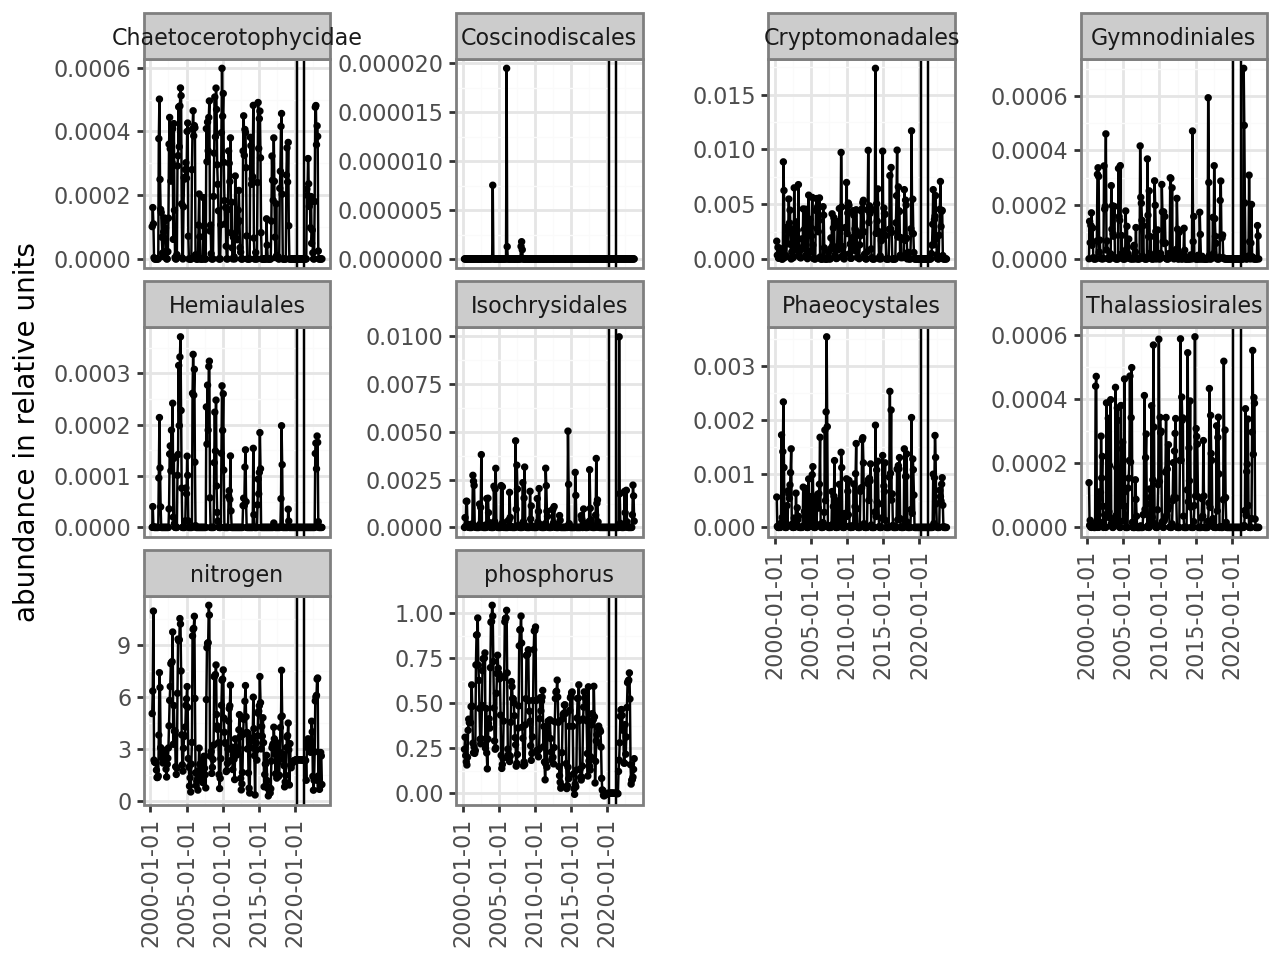

In [16]:
all_sol["month"] = [curr.month for curr in all_sol.DateTime]
all_sol["year"] = [curr.year for curr in all_sol.DateTime]
all_sol_summary = all_sol.groupby(["month","year","taxon"])[["abund","index"]].\
    mean().reset_index()
all_sol_summary["DateTime"] = [datetime(year, month, 1) for \
                               year,month in zip(all_sol_summary.year,
                                                 all_sol_summary.month)]

## plot entire timeseries
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42

zoom_in=(plotnine.ggplot(all_sol_summary.loc[(all_sol_summary["index"]>50)&\
                         ([curr in ["Phaeocystales","Thalassiosirales",
                                    "Isochrysidales","Coscinodiscales",
                                    "Chaetocerotophycidae",
                                    "Gymnodiniales",
                                    "Cryptomonadales","Hemiaulales",
                                    "nitrogen","phosphorus"] for curr in all_sol_summary.taxon]),:]) + 
    plotnine.geom_point(plotnine.aes(x="DateTime",y="abund"),size=0.5)+ 
    plotnine.geom_line(plotnine.aes(x="DateTime",y="abund",group="taxon")) + 
    #plotnine.facet_wrap("taxon",scales="free_y",ncol=1)+
    plotnine.theme_bw(base_size=10)+plotnine.ylab("abundance in relative units") + 
    plotnine.xlab("") +
    plotnine.theme(axis_text_x=plotnine.element_text(rotation=90, hjust=0.5)) +
    plotnine.facet_wrap("taxon",scales="free_y") +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2020-04-01", 
                                                                  "%Y-%m-%d"))) +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2021-04-01", 
                                                                  "%Y-%m-%d"))))
zoom_in

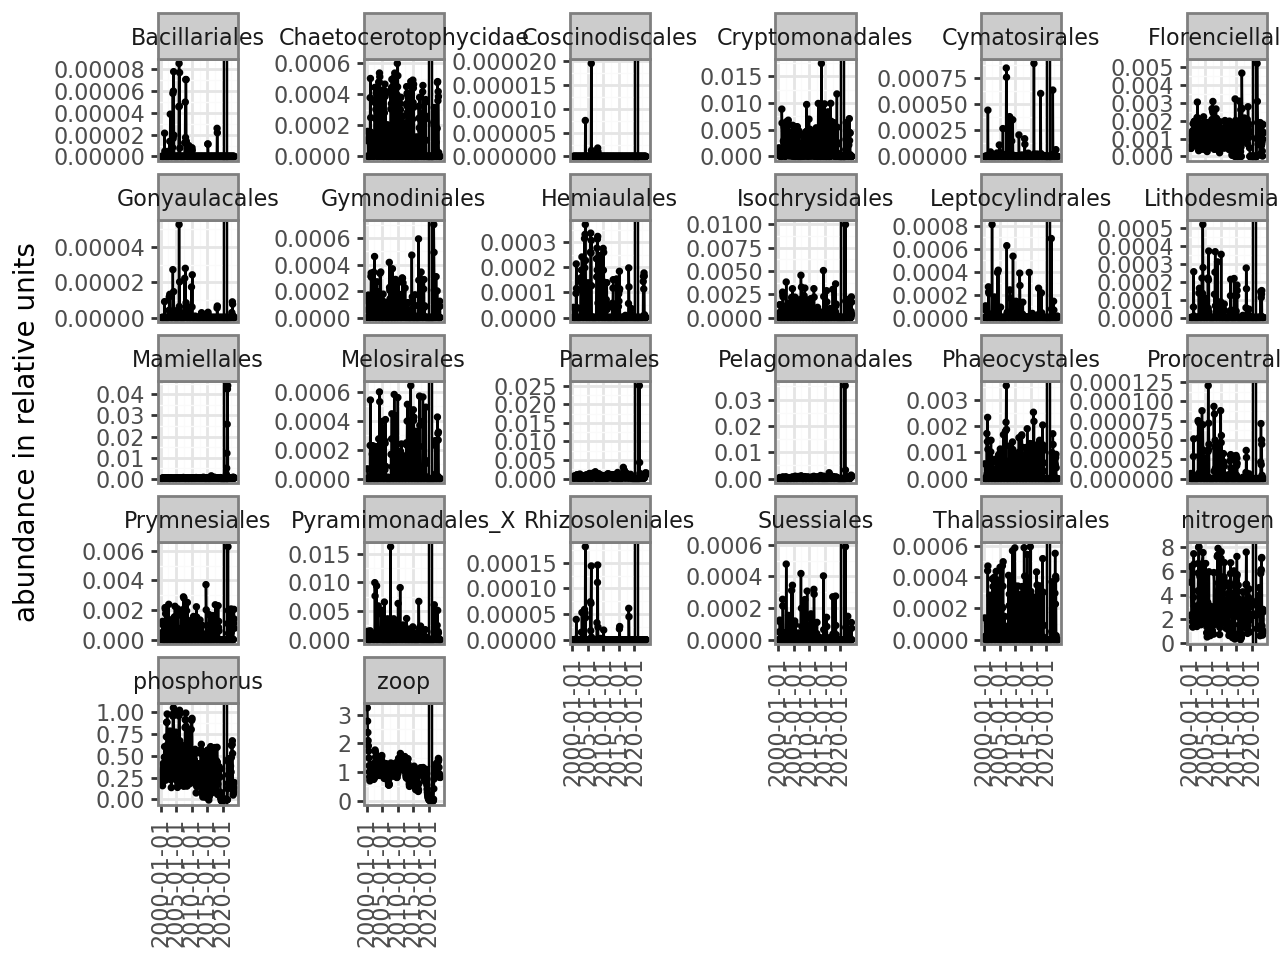

In [17]:
all_sol["month"] = [curr.month for curr in all_sol.DateTime]
all_sol["year"] = [curr.year for curr in all_sol.DateTime]
all_sol_summary = all_sol.groupby(["month","year","taxon"])[["abund","index"]].\
    mean().reset_index()
all_sol_summary = all_sol_summary.loc[all_sol_summary.abund<8]
all_sol_summary["DateTime"] = [datetime(year, month, 1) for \
                               year,month in zip(all_sol_summary.year,
                                                 all_sol_summary.month)]

## plot entire timeseries
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42

zoom_in=(plotnine.ggplot(all_sol_summary.loc[(all_sol_summary["index"]>50),:]) + 
    plotnine.geom_point(plotnine.aes(x="DateTime",y="abund"),size=0.5)+ 
    plotnine.geom_line(plotnine.aes(x="DateTime",y="abund",group="taxon")) + 
    #plotnine.facet_wrap("taxon",scales="free_y",ncol=1)+
    plotnine.theme_bw(base_size=10)+plotnine.ylab("abundance in relative units") + 
    plotnine.xlab("") +
    plotnine.theme(axis_text_x=plotnine.element_text(rotation=90, hjust=0.5)) +
    plotnine.facet_wrap("taxon",scales="free_y") +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2020-04-01", 
                                                                  "%Y-%m-%d"))) +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2021-04-01", 
                                                                  "%Y-%m-%d"))))
zoom_in

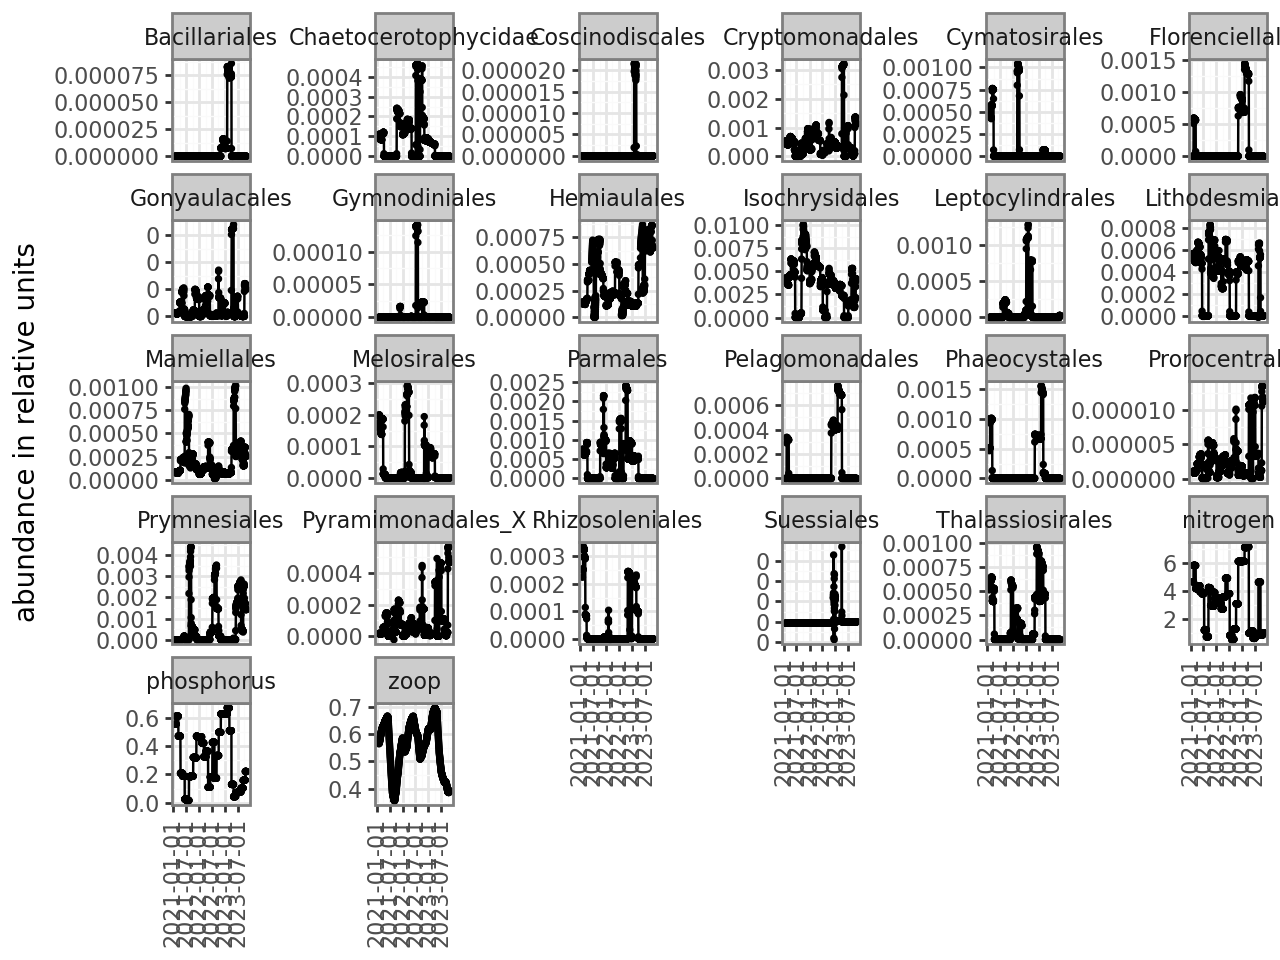

In [90]:
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42

zoom_in=(plotnine.ggplot(all_sol.loc[all_sol.DateTime>time_vect[len(time_vect)-1]-timedelta(days = 1000),:]) + 
    plotnine.geom_point(plotnine.aes(x="DateTime",y="abund"),size=0.5)+ 
    plotnine.geom_line(plotnine.aes(x="DateTime",y="abund",group="taxon")) + 
    #plotnine.facet_wrap("taxon",scales="free_y",ncol=1)+
    plotnine.theme_bw(base_size=10)+plotnine.ylab("abundance in relative units") + 
    plotnine.xlab("") +
    plotnine.theme(axis_text_x=plotnine.element_text(rotation=90, hjust=0.5)) +
    plotnine.facet_wrap("taxon",scales="free_y"))
zoom_in